# Braun et al. (2026), Fig. 4G–H and Supp. Fig. 9F–K — perturbing networks trained on experimental data (WP0.5/0.7)

> G (bat, 168 neurons): silencing 33 neurons for 0.6 s, current I = 3, noise into 50% of neurons with gain 20 for 3 s.
> H (mouse, 484 neurons): silencing 96 neurons for 32.3 s, current I = 3, noise 50% gain 3 for 161.3 s; the sequence
> resets but settles into an attractor state. Supp. 9F–H / I–K: aligned correlation curves for the bat / mouse networks.

Bat: realisation 1 of the bat-trained networks (Fig. 3 notebook; proxy data, 166 neurons, so ensembles are 16/33/49
neurons for 10/20/30%). Run length 6 s (741 steps); first half split into five 0.6-s windows (74 steps).
Mouse: skeleton; run length 322.5 s, windows of 32.3 s (3987 steps), runs once `mec.path` is set.

**Expected (legend, bat):** small current injections leave the sequence unaffected; correlations decrease with
current magnitude. Mouse: correlation ≈ 0 after release (attractor state) in most realisations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from seqnet.figures import Figure, style
from seqnet.experiments import wp0
from seqnet.models.rate_rnn import simulate, RNNParams, Perturbation
from seqnet.analysis import perturb as pt
from seqnet.data.registry import load_target
from seqnet.targets import logit_target
from seqnet.data import mec
from seqnet.experiments.runner import repo_root

style()
fig = Figure("wp0", "braun_fig4_data")
dcfg = wp0.data_config(); prm = RNNParams()
PROT = {"bat": {"n_steps": 741, "window_steps": 74, "ens": 0.2, "noise": (0.5, 20.0), "seed": 5},
        "mec": {"n_steps": 39815, "window_steps": 3987, "ens": 0.2, "noise": (0.5, 3.0), "seed": 5}}
mec_ok = mec.available(None if dcfg["mec"]["path"] is None else repo_root() / dcfg["mec"]["path"])
datasets = ["bat"] + (["mec"] if mec_ok else [])

def network(name):
    run = wp0.get_data(name, "final")
    spec = {k: v for k, v in run.meta["config"]["data"].items()}
    F, _ = load_target(spec)
    return run.W(0), logit_target(F[:, :1])[:, 0]

## Panel G (bat) / H (mouse) — unperturbed, silencing, current injection, noise injection

In [2]:
for name in datasets:
    J, h0 = network(name); p = PROT[name]; N = J.shape[0]
    ens = pt.ensembles(N, p["ens"]); ns, ws = p["n_steps"], p["window_steps"]
    sim = lambda perts: simulate(J, h0, ns, prm, np.random.default_rng(p["seed"]), perturbations=perts)["r"]
    r0 = sim([])
    E = ens[2]; w = pt.active_window(r0, E, ws, 5)
    Q = np.random.default_rng(1).choice(N, int(p["noise"][0] * N), replace=False)
    out = {"r0": r0, "rs": sim([Perturbation("silence", E, w * ws, (w + 1) * ws)]), "rc": sim([Perturbation("current", E, w * ws, (w + 1) * ws, 3.0)]),
           "rn": sim([Perturbation("noise", Q, 0, ns // 2, p["noise"][1])])}
    step = max(1, ns // 2000)
    fig.save(f"G_{name}", **{k: v[::step].T.astype(np.float32) for k, v in out.items()}, E=E, w=np.array([w * ws, (w + 1) * ws]) * prm.dt, T=ns * prm.dt)

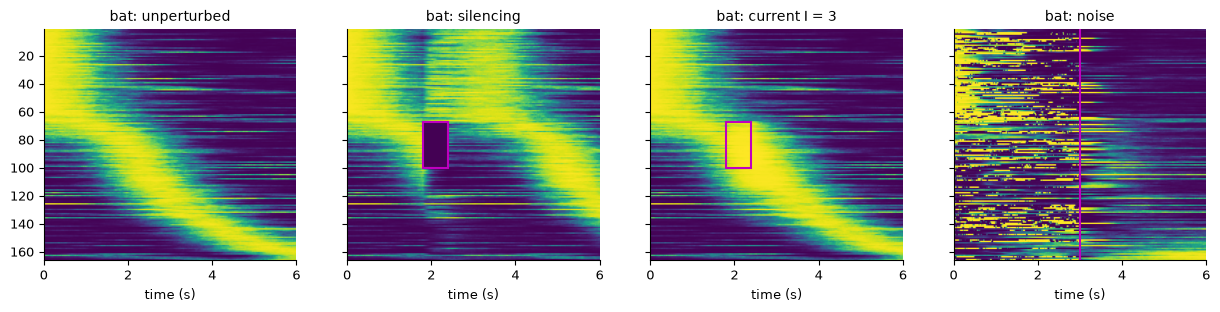

In [3]:
for name in datasets:
    d = fig.load(f"G_{name}"); T = float(d["T"]); N = d["r0"].shape[0]
    F, axs = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
    for ax, k, t in zip(axs, ["r0", "rs", "rc", "rn"], ["unperturbed", "silencing", "current I = 3", "noise"]):
        ax.imshow(d[k], aspect="auto", extent=[0, T, N, 1], vmin=0, vmax=1); ax.set_title(f"{name}: {t}"); ax.set_xlabel("time (s)")
        if k in ("rs", "rc"): ax.add_patch(plt.Rectangle((d["w"][0], d["E"][0] + 1), d["w"][1] - d["w"][0], len(d["E"]), fill=False, ec="m", lw=1.5))
        if k == "rn": ax.axvline(T / 2, color="m")
    fig.savefig(f"G_{name}", F); plt.show()

## Supp. 9F–H (bat) / I–K (mouse) — aligned correlation after release

In [4]:
for name in datasets:
    J, h0 = network(name); p = PROT[name]
    kw = dict(params=prm, n_steps=p["n_steps"], window_steps=p["window_steps"], n_windows=5, seed=p["seed"])
    cur = {}
    for f in (0.1, 0.2, 0.3):
        cur[f"silence_{f}"] = pt.structured_grid(J, h0, "silence", f, **kw).aligned_mean
        cur[f"current3_{f}"] = pt.structured_grid(J, h0, "current", f, amplitude=3.0, **kw).aligned_mean
    for I in (0.5, 2.0, 5.0):
        cur[f"currentI_{I}"] = pt.structured_grid(J, h0, "current", 0.2, amplitude=I, **kw).aligned_mean
    fig.save(f"S9_{name}", **cur)

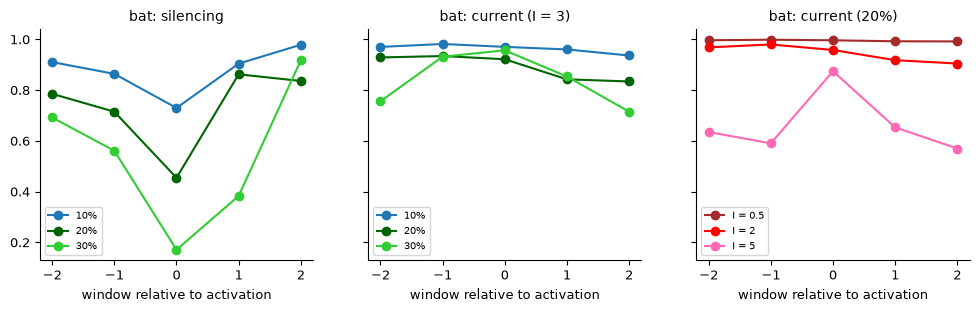

In [5]:
for name in datasets:
    d = fig.load(f"S9_{name}"); x = np.arange(-2, 3)
    F, axs = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
    for f, c in zip((0.1, 0.2, 0.3), ("tab:blue", "darkgreen", "limegreen")):
        axs[0].plot(x, d[f"silence_{f}"], "o-", color=c, label=f"{int(f*100)}%"); axs[1].plot(x, d[f"current3_{f}"], "o-", color=c, label=f"{int(f*100)}%")
    for I, c in zip((0.5, 2.0, 5.0), ("brown", "red", "hotpink")):
        axs[2].plot(x, d[f"currentI_{I}"], "o-", color=c, label=f"I = {I:g}")
    for ax, t in zip(axs, ["silencing", "current (I = 3)", "current (20%)"]): ax.set_title(f"{name}: {t}"); ax.legend(fontsize=7); ax.set_xlabel("window relative to activation")
    fig.savefig(f"S9_{name}", F); plt.show()

## Acceptance (qualitative, from the legends)

In [6]:
b = fig.load("S9_bat")
checks = [
    {"item": "bat: small current (I = 0.5) leaves the sequence unaffected", "criterion": "all aligned correlations > 0.9", "value": b["currentI_0.5"], "passed": bool(b["currentI_0.5"].min() > 0.9)},
    {"item": "bat: correlation decreases with current magnitude", "criterion": "min over windows decreasing in I", "value": [float(b[f"currentI_{I}"].min()) for I in (0.5, 2.0, 5.0)],
     "passed": bool(b["currentI_0.5"].min() >= b["currentI_2.0"].min() >= b["currentI_5.0"].min())},
    {"item": "bat: silencing curves (reported)", "criterion": "reported", "value": {f: b[f"silence_{f}"] for f in (0.1, 0.2, 0.3)}, "passed": None},
]
if "mec" in datasets:
    m = fig.load("S9_mec")
    checks.append({"item": "mouse: correlation ~0 after release (attractor)", "criterion": "median aligned silencing corr < 0.3", "value": m["silence_0.2"], "passed": bool(np.median(m["silence_0.2"]) < 0.3)})
else:
    checks.append({"item": "mouse panels (Fig. 4H, Supp. 9I-K)", "criterion": "blocked [DATA]", "value": None, "passed": None})
fig.checks(checks)

[PASS] bat: small current (I = 0.5) leaves the sequence unaffected: [0.9968069  0.99893059 0.99666625 0.99278777 0.99222546]
[PASS] bat: correlation decreases with current magnitude: [0.9922254649138769, 0.9050975455162871, 0.5701523575261661]
[info] bat: silencing curves (reported): {0.1: array([0.9107215 , 0.86434086, 0.72999588, 0.90464641, 0.97914209]), 0.2: array([0.78571751, 0.71516985, 0.45471623, 0.8625719 , 0.83634682]), 0.3: array([0.69243471, 0.56108509, 0.17120068, 0.38316599, 0.91791447])}
[info] mouse panels (Fig. 4H, Supp. 9I-K): None


WindowsPath('C:/Users/max/Documents/phd-work/results/wp0/data/braun_fig4_data/acceptance.json')